In [1]:
!pip install kaggle

In [2]:
from google.colab import files
files.upload()

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"rofaidasamy","key":"2dbb2f8ed656b7e14de5f44e50184016"}'}

In [3]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

In [4]:
!kaggle datasets download -d zawarkhan69/human-facial-expression-dataset

Dataset URL: https://www.kaggle.com/datasets/zawarkhan69/human-facial-expression-dataset
License(s): CC0-1.0
  0% 0.00/24.7M [00:00<?, ?B/s]
100% 24.7M/24.7M [00:00<00:00, 1.72GB/s]


In [5]:
!unzip human-facial-expression-dataset.zip -d ./human_facial_expression

Archive:  human-facial-expression-dataset.zip
  inflating: ./human_facial_expression/Dataset(Final)/test/Angry_human_face/flipped_amazed-astonished-bearded-guy-looks-displeasure-frowns-face-angrily_273609-17014.jpg_face_0.jpg  
  inflating: ./human_facial_expression/Dataset(Final)/test/Angry_human_face/flipped_angry-furious-hispanic-man-rage-portrait_93675-94669.jpg_face_0.jpg  
  inflating: ./human_facial_expression/Dataset(Final)/test/Angry_human_face/flipped_angry-grumpy-young-bearded-man-posing_176420-30315.jpg_face_0.jpg  
  inflating: ./human_facial_expression/Dataset(Final)/test/Angry_human_face/flipped_angry-man-shouting-pointing-finger-beige-wall_176420-113.jpg_face_0.jpg  
  inflating: ./human_facial_expression/Dataset(Final)/test/Angry_human_face/flipped_angry-man-shouts-furiously-keeps-mouth-widely-opened-feels-terrible-pain-dressed-jean-shirt_273609-16788.jpg_face_0.jpg  
  inflating: ./human_facial_expression/Dataset(Final)/test/Angry_human_face/flipped_cannot-handle-feel

In [6]:
!ls

human_facial_expression		     kaggle.json
human-facial-expression-dataset.zip  sample_data


In [7]:
import zipfile

with zipfile.ZipFile("human-facial-expression-dataset.zip", 'r') as zip_ref:
    zip_ref.extractall("human_facial_expression")

In [8]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from sklearn.model_selection import train_test_split
from google.colab.patches import cv2_imshow
from PIL import Image, ImageFilter

import os
import kagglehub
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras import layers, models
import gradio as gr

import zipfile


In [9]:
file_names = os.listdir('/content/human_facial_expression/Dataset(Final)/train')

for i in range(5):
  name = file_names[i]
  print(name[0:30])

Surprised_human_face
Happy_human_face
Sad_human_face
Neutral_human_face
Angry_human_face


In [10]:
path, dirs, files = next(os.walk('/content/human_facial_expression/Dataset(Final)/train/Happy_human_face'))
file_count = len(files)
print('Number of happy images: ', file_count)

Number of happy images:  327


In [11]:
path, dirs, files = next(os.walk('/content/human_facial_expression/Dataset(Final)/train/Angry_human_face'))
file_count = len(files)
print('Number of angry images: ', file_count)

Number of angry images:  284


In [12]:
path, dirs, files = next(os.walk('/content/human_facial_expression/Dataset(Final)/train/Sad_human_face'))
file_count = len(files)
print('Number of sad images: ', file_count)

Number of sad images:  248


In [13]:
path, dirs, files = next(os.walk('/content/human_facial_expression/Dataset(Final)/train/Surprised_human_face'))
file_count = len(files)
print('Number of surprised images: ', file_count)

Number of surprised images:  306


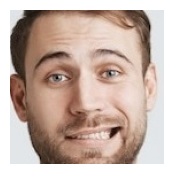

In [14]:
img = mpimg.imread('/content/human_facial_expression/Dataset(Final)/train/Happy_human_face/flipped_awkward-smiling-man-feel-indecisive_176420-18009.jpg_face_0.jpg')
plt.figure(figsize=(2,2))
imgplt = plt.imshow(img, cmap='gray')
plt.axis('off')
plt.show()

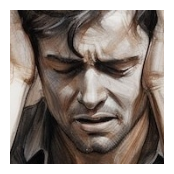

In [15]:
img = mpimg.imread('/content/human_facial_expression/Dataset(Final)/train/Sad_human_face/flipped_angry-man-hand-draw-sketch_862994-19814.jpg_face_0.jpg')
plt.figure(figsize=(2,2))
imgplt = plt.imshow(img, cmap='gray')
plt.axis('off')
plt.show()

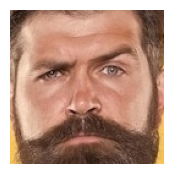

In [16]:
img = mpimg.imread('/content/human_facial_expression/Dataset(Final)/train/Angry_human_face/flipped_bearded-man-with-hairstyle-white-shirt-male-fashion_474717-141714.jpg_face_0.jpg')
plt.figure(figsize=(2,2))
imgplt = plt.imshow(img, cmap='gray')
plt.axis('off')
plt.show()

In [17]:
path = kagglehub.dataset_download("zawarkhan69/human-facial-expression-dataset")
print("Dataset path:", path)
print("Files inside dataset:", os.listdir(path))

100%|██████████| 24.7M/24.7M [00:00<00:00, 175MB/s]

Extracting files...


Dataset path: /root/.cache/kagglehub/datasets/zawarkhan69/human-facial-expression-dataset/versions/1
Files inside dataset: ['Dataset(Final)']


In [18]:
if path.endswith(".zip"):
    extract_dir = "./human_facial_expression"
    with zipfile.ZipFile(path, 'r') as zip_ref:
        zip_ref.extractall(extract_dir)
    print("Files extracted to:", extract_dir)
else:
    extract_dir = path

In [19]:
print("Files and folders inside extract_dir:")
print(os.listdir(extract_dir))


Files and folders inside extract_dir:
['Dataset(Final)']


In [20]:
dataset_root = os.path.join(extract_dir, "Dataset(Final)")

train_dir = os.path.join(dataset_root, "train")
test_dir  = os.path.join(dataset_root, "test")

print("Train dir exists:", os.path.exists(train_dir))
print("Train classes:", os.listdir(train_dir))

print("Test dir exists:", os.path.exists(test_dir))
print("Test classes:", os.listdir(test_dir))

Train dir exists: True
Train classes: ['Surprised_human_face', 'Happy_human_face', 'Sad_human_face', 'Neutral_human_face', 'Angry_human_face']
Test dir exists: True
Test classes: ['Surprised_human_face', 'Happy_human_face', 'Sad_human_face', 'Neutral_human_face', 'Angry_human_face']


In [21]:
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    validation_split=0.2
)

In [22]:
train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(224,224),
    color_mode='grayscale',
    batch_size=64,
    class_mode="categorical",
    subset="training"
)

Found 1170 images belonging to 5 classes.


In [23]:
val_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(224,224),
    color_mode='grayscale',
    batch_size=64,
    class_mode="categorical",
    subset="validation"
)

Found 289 images belonging to 5 classes.


In [24]:
test_datagen = ImageDataGenerator(rescale=1./255)

In [25]:
test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=(224,224),
    color_mode="grayscale",
    batch_size=64,
    class_mode="categorical",
    shuffle=False
)

Found 181 images belonging to 5 classes.


In [26]:
from tensorflow.keras.applications import MobileNetV2
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224,224, 3)
)

# تجميد الأوزان عشان ما تتدربش من الأول
base_model.trainable = False

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [46]:
model = models.Sequential([
    layers.Conv2D(32, (3,3), activation="relu", padding="same", input_shape=(224,224,1)),
    layers.BatchNormalization(),
    layers.MaxPooling2D(2,2),

    layers.Conv2D(64, (3,3), activation="relu", padding="same"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(2,2),

    layers.Conv2D(128, (3,3), activation="relu", padding="same"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(2,2),

    layers.Conv2D(256, (3,3), activation="relu", padding="same"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(2,2),

    layers.GlobalAveragePooling2D(),

    layers.Dense(256, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.4),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),

    layers.Dense(train_generator.num_classes, activation="softmax")
])

In [47]:
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_28 (Conv2D)              │ (None, 224, 224, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_28          │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_28 (MaxPooling2D) │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_29 (Conv2D)              │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_29          │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_29 (MaxPooling2D) │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_30 (Conv2D)              │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_30          │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_30 (MaxPooling2D) │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_31 (Conv2D)              │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_31          │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_31 (MaxPooling2D) │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_32          │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 490,117 (1.87 MB)

 Trainable params: 488,645 (1.86 MB)

 Non-trainable params: 1,472 (5.75 KB)

In [48]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

callbacks = [

    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5)
]

history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=100,
    callbacks=callbacks
)

Epoch 1/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 33s 1s/step - accuracy: 0.2512 - loss: 2.0654 - val_accuracy: 0.2007 - val_loss: 1.6239 - learning_rate: 0.0010
Epoch 2/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 7s 351ms/step - accuracy: 0.2995 - loss: 1.8244 - val_accuracy: 0.1280 - val_loss: 1.7288 - learning_rate: 0.0010
Epoch 3/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 8s 399ms/step - accuracy: 0.3210 - loss: 1.7259 - val_accuracy: 0.2007 - val_loss: 2.0217 - learning_rate: 0.0010
Epoch 4/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 7s 371ms/step - accuracy: 0.3343 - loss: 1.6685 - val_accuracy: 0.2007 - val_loss: 2.1674 - learning_rate: 0.0010
Epoch 5/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 7s 369ms/step - accuracy: 0.3893 - loss: 1.6187 - val_accuracy: 0.2007 - val_loss: 2.4815 - learning_rate: 0.0010
Epoch 6/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 8s 400ms/step - accuracy: 0.3901 - loss: 1.5227 - val_accuracy: 0.2007 - val_loss: 2.6916 - learning_rate: 0.0010
Epoch 7/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 7s 361ms/step - accuracy: 0.3853 - loss: 1.50

In [49]:
test_loss, test_acc = model.evaluate(test_generator)
print(f"Test accuracy: {test_acc:.2f}")

3/3 ━━━━━━━━━━━━━━━━━━━━ 3s 1s/step - accuracy: 0.6482 - loss: 0.9489
Test accuracy: 0.65


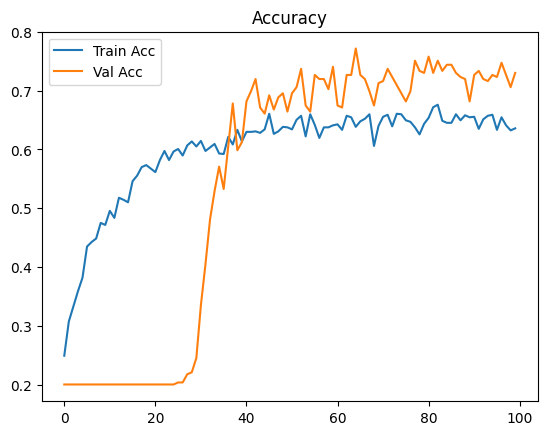

In [ ]:
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.legend()
plt.title("Accuracy")
plt.show()

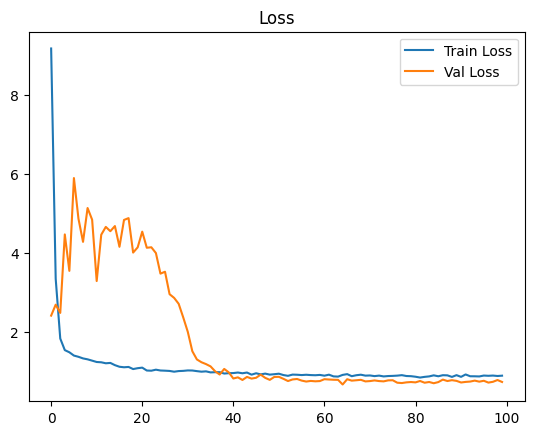

In [ ]:
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.legend()
plt.title("Loss")
plt.show()

In [ ]:
labels = list(train_generator.class_indices.keys())

def predict_emotion(img):
    img = Image.fromarray(img).convert("L").resize((224,224))
    img = np.array(img)/255.0
    img = img.reshape(1, 224, 224, 1)
    pred = model.predict(img)[0]
    idx = np.argmax(pred)
    return {labels[i]: float(pred[i]) for i in range(len(labels))}

iface = gr.Interface(
    fn=predict_emotion,
    inputs=gr.Image(type="numpy"),
    outputs=gr.Label(num_top_classes=3),
    live=False,
    title="Human Facial Expression Recognition"
)

iface.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://4284f9be12a7f588c8.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
